## 1. Chuẩn hóa & Tổng hợp Metrics (`evaluation_results.csv`)

Cell code bên dưới thực hiện thu thập kết quả đánh giá của cả ba mô hình từ thư mục `results/metrics/`, chuẩn hóa về cùng một định dạng 9 chỉ số chung và xuất ra file tổng hợp cuối cùng:

- **Dữ liệu đầu vào (`results/metrics/`):**
  - `baseline_metrics.csv` (TF-IDF + Logistic Regression)
  - `frozen_encoder_metrics.csv` (DistilBERT Frozen Encoder)
  - `fine_tuning_metrics.csv` (DistilBERT Fine-Tuning)
- **Tệp kết quả đầu ra:** `results/metrics/evaluation_results.csv` *(tệp này nằm trong danh sách loại trừ của `.gitignore` nên sẽ tự động được sinh ra cục bộ trên máy khi chạy cell code bên dưới)*.

,Model,Accuracy,Precision,Recall,Macro F1-score,Training Time (s),Inference Time (s),Trainable Parameters,Model Size (MB)
0,baseline,0.918026,0.917902,0.918026,0.917835,48.220558,1.054899,200004,3.408657
1,frozen_encoder,0.903421,0.903551,0.903421,0.903245,3289.519261,182.527057,3076,253.169937
2,fine_tuning,0.942237,0.942432,0.942237,0.942283,2028.193505,14.145391,66365956,253.169937


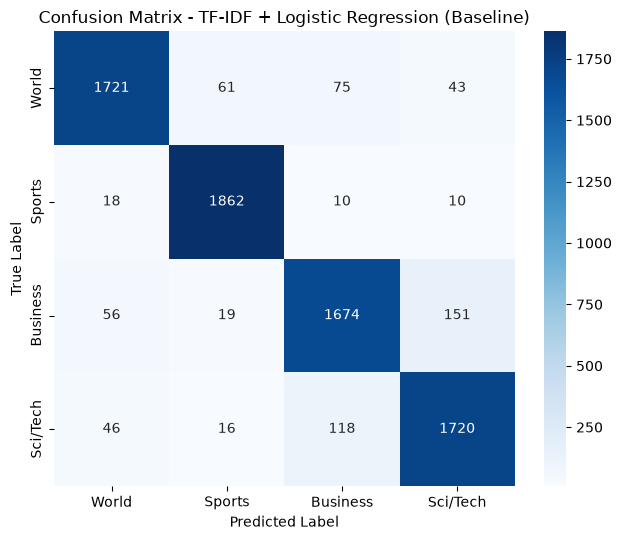

Đã lưu: C:\Course-Work-6-main\results\figures\confusion_matrix_baseline.png


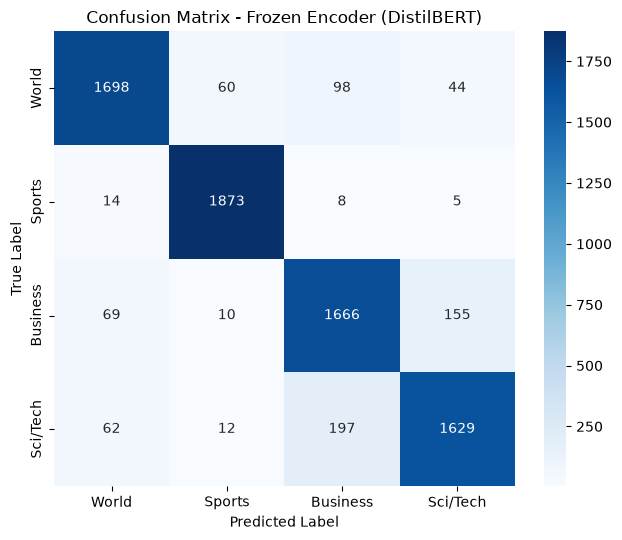

Đã lưu: C:\Course-Work-6-main\results\figures\confusion_matrix_frozen_encoder.png


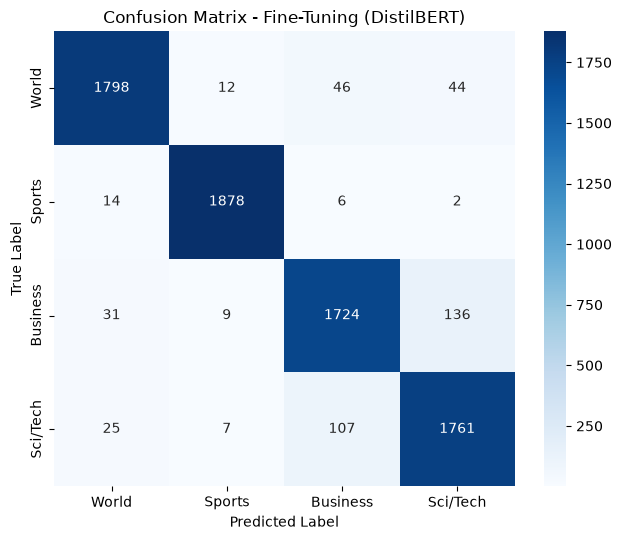

Đã lưu: C:\Course-Work-6-main\results\figures\confusion_matrix_fine_tuning.png


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
METRICS_DIR = ROOT / "results" / "metrics"
FIGURES_DIR = ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

# 1. Chọn đúng 9 cột chuẩn chung từ các file metrics và đổi tên đẹp cho bảng báo cáo
COLS_TO_KEEP = [
    "model",
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "train_time_s",
    "inference_time_s",
    "trainable_params",
    "model_size_mb",
]

RENAME_TO_DISPLAY = {
    "model": "Model",
    "accuracy": "Accuracy",
    "precision_macro": "Precision",
    "recall_macro": "Recall",
    "f1_macro": "Macro F1-score",
    "train_time_s": "Training Time (s)",
    "inference_time_s": "Inference Time (s)",
    "trainable_params": "Trainable Parameters",
    "model_size_mb": "Model Size (MB)",
}

metric_files = [
    METRICS_DIR / "baseline_metrics.csv",
    METRICS_DIR / "frozen_encoder_metrics.csv",
    METRICS_DIR / "fine_tuning_metrics.csv",
]

frames = []
for f in metric_files:
    if f.exists():
        df = pd.read_csv(f)[COLS_TO_KEEP].rename(columns=RENAME_TO_DISPLAY)
        frames.append(df)
    else:
        print(f"Đang chờ file: {f.name}")

if frames:
    eval_df = pd.concat(frames, ignore_index=True)
    eval_df.to_csv(METRICS_DIR / "evaluation_results.csv", index=False)
    display(eval_df)

# 2. Vẽ, lưu và hiển thị Confusion Matrix từ các file predictions
pred_configs = [
    ("TF-IDF + Logistic Regression (Baseline)", METRICS_DIR / "baseline_test_predictions.csv", FIGURES_DIR / "confusion_matrix_baseline.png"),
    ("Frozen Encoder (DistilBERT)", METRICS_DIR / "frozen_encoder_predictions.csv", FIGURES_DIR / "confusion_matrix_frozen_encoder.png"),
    ("Fine-Tuning (DistilBERT)", METRICS_DIR / "fine_tuning_predictions.csv", FIGURES_DIR / "confusion_matrix_fine_tuning.png"),
]

for title, pred_path, fig_path in pred_configs:
    if pred_path.exists():
        df_pred = pd.read_csv(pred_path)
        cm = confusion_matrix(df_pred["true_label"], df_pred["pred_label"])
        plt.figure(figsize=(6.5, 5.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
        plt.title(f"Confusion Matrix - {title}")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.tight_layout()
        plt.savefig(fig_path, dpi=300)
        plt.show()
        print(f"Đã lưu: {fig_path}")
    else:
        print(f"Đang chờ file predictions: {pred_path.name}")

## 2. Biểu đồ So sánh Hiệu năng và Chi phí Tính toán

Trực quan hóa sự đánh đổi (trade-off) giữa chất lượng phân loại (**Accuracy, Precision, Recall, Macro F1-score**) và chi phí tài nguyên (**Training Time, Inference Time, Trainable Parameters, Model Size**) giữa 3 phương pháp tiếp cận.

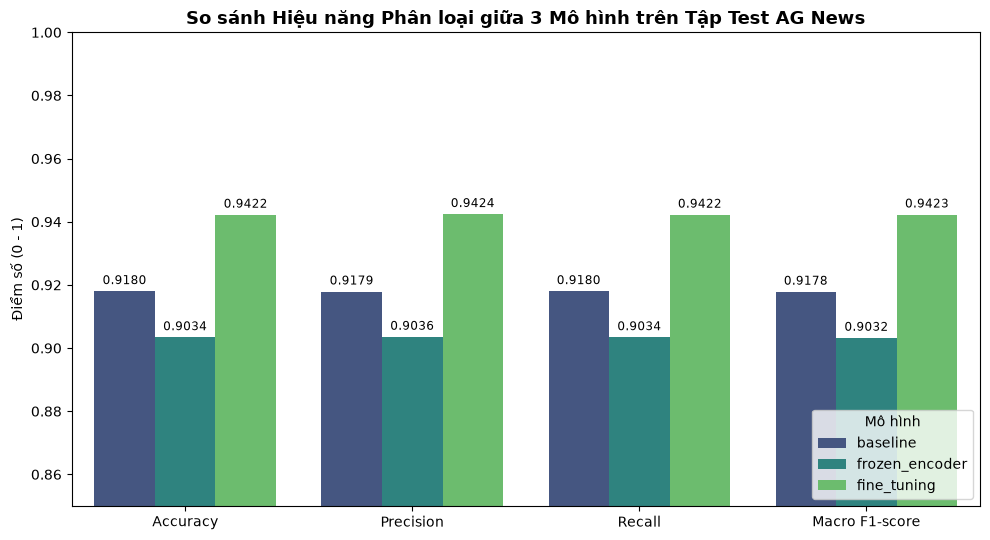

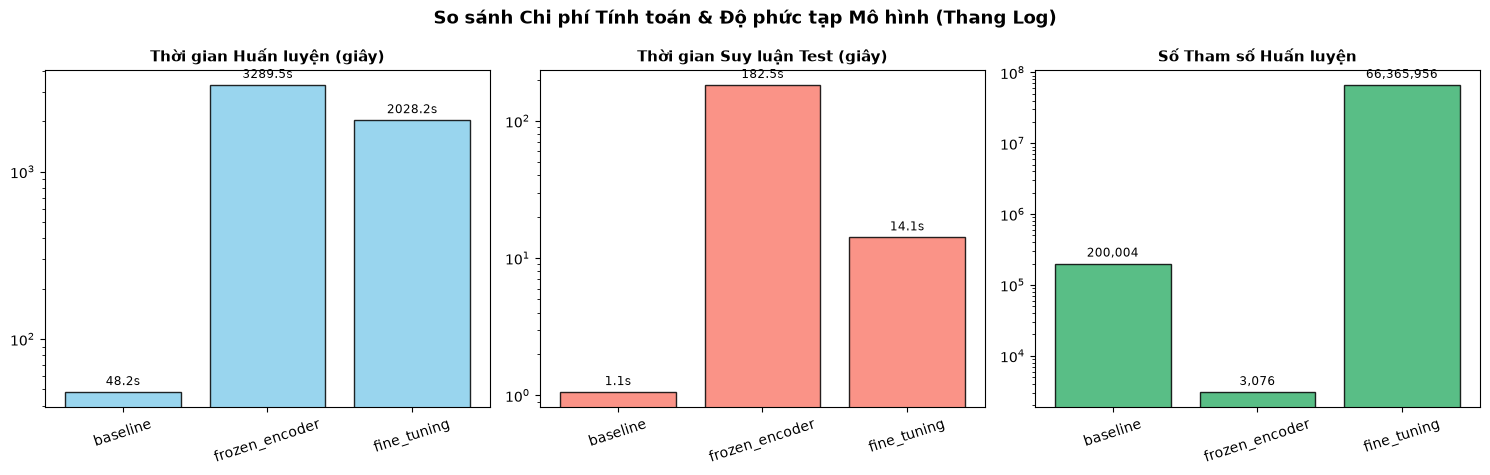

In [3]:
# Biểu đồ 2A: So sánh 4 chỉ số chất lượng phân loại (Accuracy, Precision, Recall, Macro F1)
quality_cols = ["Accuracy", "Precision", "Recall", "Macro F1-score"]
df_melted = eval_df.melt(id_vars="Model", value_vars=quality_cols, var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=df_melted, x="Metric", y="Score", hue="Model", palette="viridis")
plt.ylim(0.85, 1.0)
plt.title("So sánh Hiệu năng Phân loại giữa 3 Mô hình trên Tập Test AG News", fontsize=13, fontweight="bold")
plt.ylabel("Điểm số (0 - 1)")
plt.xlabel("")
plt.legend(title="Mô hình", loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=8.5, padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparison_classification_metrics.png", dpi=300)
plt.show()

# Biểu đồ 2B: So sánh Thời gian Huấn luyện, Thời gian Suy luận và Số Tham số Huấn luyện
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

resource_specs = [
    ("Training Time (s)", "Thời gian Huấn luyện (giây)", "skyblue"),
    ("Inference Time (s)", "Thời gian Suy luận Test (giây)", "salmon"),
    ("Trainable Parameters", "Số Tham số Huấn luyện", "mediumseagreen"),
]

for ax, (col, title, color) in zip(axes, resource_specs):
    bars = ax.bar(eval_df["Model"], eval_df[col], color=color, edgecolor="black", alpha=0.85)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", rotation=18)
    ax.set_yscale("log")  # Dùng thang log để hiển thị rõ sự chênh lệch lớn giữa TF-IDF và DistilBERT
    for bar in bars:
        val = bar.get_height()
        label = f"{int(val):,}" if col == "Trainable Parameters" else f"{val:.1f}s"
        ax.annotate(label, (bar.get_x() + bar.get_width() / 2, val),
                    ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

plt.suptitle("So sánh Chi phí Tính toán & Độ phức tạp Mô hình (Thang Log)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparison_computational_cost.png", dpi=300)
plt.show()

## 3. Phân tích Lỗi sai Chi tiết (Error Analysis)

Đánh giá chi tiết Precision/Recall/F1 trên từng nhãn (**World, Sports, Business, Sci/Tech**), xác định cặp nhãn dễ bị nhầm lẫn nhất và trích xuất các mẫu dự đoán sai điển hình để lý giải nguyên nhân.

In [4]:
# 1. In Classification Report chi tiết từng lớp cho cả 3 mô hình
for title, pred_path, _ in pred_configs:
    if pred_path.exists():
        df_p = pd.read_csv(pred_path)
        print("=" * 70)
        print(f"CLASSIFICATION REPORT: {title}")
        print("=" * 70)
        print(classification_report(df_p["true_label"], df_p["pred_label"], target_names=LABEL_NAMES, digits=4))

# 2. Phân tích cặp nhãn nhầm lẫn nhiều nhất & ví dụ lỗi sai trên mô hình tốt nhất (Fine-Tuning)
ft_pred_path = METRICS_DIR / "fine_tuning_predictions.csv"
if ft_pred_path.exists():
    df_ft = pd.read_csv(ft_pred_path)
    df_ft["true_name"] = df_ft["true_label"].map(lambda i: LABEL_NAMES[i])
    df_ft["pred_name"] = df_ft["pred_label"].map(lambda i: LABEL_NAMES[i])
    
    errors = df_ft[df_ft["true_label"] != df_ft["pred_label"]].copy()
    print(f"\nTổng số mẫu dự đoán sai của Fine-Tuning: {len(errors)} / {len(df_ft)} ({len(errors)/len(df_ft)*100:.2f}%)")
    
    # Thống kê top các cặp nhầm lẫn phổ biến nhất
    confusion_pairs = (
        errors.groupby(["true_name", "pred_name"])
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
    )
    print("\nTop các cặp nhãn bị nhầm lẫn nhiều nhất (Fine-Tuning):")
    display(confusion_pairs)

    # Hiển thị 10 mẫu văn bản dự đoán sai điển hình (nếu file predictions có cột text)
    text_col = next((c for c in ["text", "sentence", "input_text", "title"] if c in errors.columns), None)
    if text_col:
        print("\nMột số mẫu tin tức bị phân loại nhầm điển hình:")
        display(errors[[text_col, "true_name", "pred_name"]].head(10))

CLASSIFICATION REPORT: TF-IDF + Logistic Regression (Baseline)
              precision    recall  f1-score   support

       World     0.9348    0.9058    0.9201      1900
      Sports     0.9510    0.9800    0.9653      1900
    Business     0.8918    0.8811    0.8864      1900
    Sci/Tech     0.8940    0.9053    0.8996      1900

    accuracy                         0.9180      7600
   macro avg     0.9179    0.9180    0.9178      7600
weighted avg     0.9179    0.9180    0.9178      7600

CLASSIFICATION REPORT: Frozen Encoder (DistilBERT)
              precision    recall  f1-score   support

       World     0.9213    0.8937    0.9073      1900
      Sports     0.9581    0.9858    0.9717      1900
    Business     0.8461    0.8768    0.8612      1900
    Sci/Tech     0.8887    0.8574    0.8728      1900

    accuracy                         0.9034      7600
   macro avg     0.9036    0.9034    0.9032      7600
weighted avg     0.9036    0.9034    0.9032      7600

CLASSIFICATION R

,true_name,pred_name,Count
0,Business,Sci/Tech,136
3,Sci/Tech,Business,107
9,World,Business,46
10,World,Sci/Tech,44
2,Business,World,31
5,Sci/Tech,World,25
8,Sports,World,14
11,World,Sports,12
1,Business,Sports,9
4,Sci/Tech,Sports,7



Một số mẫu tin tức bị phân loại nhầm điển hình:


,text,true_name,pred_name
20,IBM to hire even more new workers By the end o...,Sci/Tech,Business
23,Some People Not Eligible to Get in on Google I...,Sci/Tech,Business
24,Rivals Try to Turn Tables on Charles Schwab By...,Sci/Tech,Business
36,Venezuela Prepares for Chavez Recall Vote Supp...,World,Business
47,Dell Exits Low-End China Consumer PC Market HO...,Sci/Tech,Business
83,Intel to delay product aimed for high-definiti...,Business,Sci/Tech
110,Yahoo! Ups Ante for Small Businesses Web giant...,Business,Sci/Tech
111,IBM Buys Two Danish Services Firms IBM said Tu...,Sci/Tech,Business
120,Oil prices bubble to record high The price of ...,World,Business
126,Security scare as intruder dives in A CANADIAN...,Sports,World
